<div align="center">
    <span style="font-size:30px">
        <strong>
            <!-- Título del proyecto -->
            Prospectivity for "U - REE" - Peru Central
        </strong>
    </span>
    <br>
    <span style="font-size:16px">
        ¿Coinciden los datos públicos? Validación de fuentes de gravimetría y de uranio en roca
    </span>
    <br><br>
    <span>
        <!-- Repositorio del proyecto -->
        <a href="https://github.com/HeisenbergPy/Prospectivity-for-U-REE-Peru-Central" target="_blank">
            <img src="https://img.shields.io/badge/GitHub-repositorio-181717?logo=github">
        </a>
        &nbsp;&nbsp;
        <!-- Versión de Python -->
        <img src="https://img.shields.io/badge/Python-3.12-3776AB?logo=python&logoColor=white">
        &nbsp;&nbsp;
        <!-- Licencia -->
        <img src="https://img.shields.io/badge/licencia-MIT-forestgreen">
        &nbsp;&nbsp;
        <!-- Entorno -->
        <img src="https://img.shields.io/badge/entorno-uv-de5fe9">
    </span>
    <br>
    <span>
        <!-- Curso -->
        <img src="https://img.shields.io/badge/PUCP-Geocomputaci%C3%B3n%201GEO20-1d3557">
        &nbsp;&nbsp;
        <!-- Semestre -->
        <img src="https://img.shields.io/badge/semestre-2026--II-e8761a">
    </span>
    <br>
    <span>
        <strong>Carlos Manuel Gutiérrez Cruzado</strong> &nbsp;|&nbsp; <strong>Félix Bryan Cordero Escobar</strong>
    </span>
    <br>
    <span>Pontificia Universidad Católica del Perú</span>
</div>

***

<span style="color:#e8761a; font-size:25px">**GC03 - Relación del uranio con otras variables**</span>

Entrega final del Trabajo Final de **Geocomputación (1GEO20)**, semestre 2026-II.

Este cuaderno responde la tercera pregunta del trabajo: con qué variables se relaciona el
<span style="color:#2a9d8f">uranio en roca</span>. Se analizan el torio y el SiO₂ de la misma roca, el berilio de los
<span style="color:#2a9d8f">sedimentos de quebrada</span> cercanos y la <span style="color:#2a9d8f">anomalía de
Bouguer</span> del modelo XGM2019e, con las fuentes ya validadas en GC02.

<span style="color:#2a9d8f; font-size:20px">**Contenido**</span>

***
- [Descripción general](#descripcion)
- [1. Librerías y datos](#parte-1)
- [2. Uranio y torio](#parte-2)
- [3. Uranio y SiO₂](#parte-3)
- [4. Uranio en roca y berilio en sedimentos](#parte-4)
- [5. Uranio y gravedad](#parte-5)
- [6. Síntesis: matriz de correlaciones](#parte-6)
- [7. Conclusiones](#parte-7)
- [Declaración de uso de inteligencia artificial](#ia)
- [Referencias](#referencias)

***

<a id="descripcion"></a>

## <span style="color:#e8761a">**DESCRIPCIÓN GENERAL**</span>
***

### Objetivo

Establecer con qué variables se relaciona el uranio en roca y si esas relaciones son útiles para la prospección.
Cada variable responde a una hipótesis geológica distinta:

| Variable | Hipótesis | Qué se espera |
|---|---|---|
| Th en la misma roca | U y Th son incompatibles y se concentran juntos en el magma; el U, además, se moviliza al oxidarse (Cuney, 2014) | Correlación fuerte; Th/U < 1 donde hubo U añadido |
| SiO₂ en la misma roca | El U se acumula en los fundidos más diferenciados | U creciente con el SiO₂ |
| Be en el sedimento de quebrada | El Be es otro elemento incompatible de los granitos evolucionados; el sedimento integra la cuenca | Más Be cerca de las rocas con más U |
| Anomalía de Bouguer | Los granitos son menos densos que su encajante | U alto en anomalías relativamente negativas |

| Técnica | Sección |
|---|---|
| Correlación de Spearman y recta en escala logarítmica con intervalo de confianza | 2 y 3 |
| Vecino más cercano y agregación en celdas | 4 |
| Separación regional-residual y correlación parcial | 5 |
| Matriz de correlaciones | 6 |

Las rocas son las rocas de caja depuradas en GC02 (`lectura.rocas_de_caja`), y las correlaciones se calculan por
fuente cuando estas difieren, porque GC02 mostró que BDG 2022 se muestreó sobre todo en labores mineras.

<a id="parte-1"></a>

## <span style="color:#e8761a">**1. LIBRERÍAS Y DATOS**</span>
***

Se emplean los mismos módulos que en GC02. La gravedad se toma de la grilla del modelo evaluada en la superficie
(`gravedad_XGM2019e_bouguer_superficie.tif`), que en GC02 concordó mejor con las estaciones que la grilla a h = 0.

In [1]:
'''Importamos las librerías que usaremos'''

import numpy as np                           # Cálculo numérico
import pandas as pd                          # Tablas
import geopandas as gpd                      # Vectores (SHP)
from scipy import stats                      # Pruebas estadísticas
import matplotlib.pyplot as plt              # Gráficos
from matplotlib.colors import TwoSlopeNorm   # Escala de color centrada en 0
'''Funciones propias del trabajo (carpeta geocomp/)'''
from geocomp import lectura, espacial, estadistica, gravedad
from geocomp import graficos as graf
from geocomp.rutas import ARCHIVOS

'''Estilo común de las figuras'''
graf.aplicar_estilo()
pd.set_option('display.precision', 2)

In [2]:
'''Rocas de caja depuradas en GC02: U medido, sin menas ni vetas y con las réplicas unidas'''
aoi = lectura.cargar_aoi()
rocas = lectura.rocas_de_caja(lectura.cargar_uranio())
rocas['Th_U'] = rocas.Th_ppm / rocas.U_ppm

'''Sedimentos de quebrada con Be medido y relieve para los mapas'''
sedimentos = lectura.cargar_sedimentos()
sed_be = sedimentos[sedimentos.Be_ppm.notna()]
elevacion, extension = espacial.raster_a_utm(ARCHIVOS['dem_90m'], aoi, celda=250)

print(f'Rocas de caja: {len(rocas)} | con Th: {(rocas.Th_ppm > 0).sum()} | con SiO2: {rocas.SiO2_pct.notna().sum()}')
print(f'Sedimentos: {len(sedimentos)} | con Be medido: {len(sed_be)}')
rocas.fuente.value_counts().reindex(lectura.FUENTES_U).to_frame('rocas de caja').T

Rocas de caja: 587 | con Th: 554 | con SiO2: 453
Sedimentos: 720 | con Be medido: 591


fuente,Litogeoquímica,BDG 2022,GE27,IPEN,B-74
rocas de caja,325,208,32,19,3


Antes de correlacionar el Be conviene revisar su resolución: si muchos valores están en el límite de detección, la
variable tiene pocos niveles y la correlación pierde sensibilidad.

In [3]:
'''Estado del dato de Be en la capa original de sedimentos'''
be_original = gpd.read_file(ARCHIVOS['sedimentos'])['BE_PPM']
print(lectura.estado(be_original).value_counts().to_dict())
print('Valores más frecuentes (ppm):', sed_be.Be_ppm.value_counts().head(4).to_dict())

{'numero': 591, '<LD': 129}
Valores más frecuentes (ppm): {0.6: 116, 0.7: 81, 0.8: 78, 0.5: 44}


***

<a id="parte-2"></a>

## <span style="color:#e8761a">**2. URANIO Y TORIO**</span>
***

En una roca ígnea sin alteración, el U y el Th se comportan de forma parecida y su razón se mantiene cerca de 4
(Cuney, 2014). Si la relación es proporcional, la recta log10(Th) frente a log10(U) tiene pendiente 1; una pendiente
menor indica que el U aumenta más que el Th, como ocurre cuando se añade U por procesos hidrotermales o de
meteorización.

In [4]:
'''Fuentes con Th medido y suficientes rocas (B-74 tiene solo 3 rocas de caja)'''
FUENTES_TH = ['Litogeoquímica', 'BDG 2022', 'IPEN']
con_th = rocas[rocas.Th_ppm > 0]

'''Correlación de Spearman y recta log10(Th) = a + b·log10(U) en cada fuente'''
filas = []
for fuente in FUENTES_TH:
    t = con_th[con_th.fuente == fuente]
    rho, p = stats.spearmanr(t.U_ppm, t.Th_ppm)
    ajuste = estadistica.regresion_log(t.U_ppm, t.Th_ppm, log_x=True)
    filas.append({'fuente': fuente, 'n': len(t), 'ρ de Spearman': rho, 'p': p, 'pendiente b': ajuste['pendiente'],
                  'IC 95 % de b': f'{ajuste["pend_inf"]:.2f} a {ajuste["pend_sup"]:.2f}', 'r²': ajuste['r2'],
                  'Th/U mediana': t.Th_U.median()})
relacion_th = pd.DataFrame(filas).set_index('fuente')
relacion_th

,n,ρ de Spearman,p,pendiente b,IC 95 % de b,r²,Th/U mediana
fuente,,,,,,,
Litogeoquímica,325,0.81,1.52e-77,0.96,0.89 a 1.03,0.69,4.27
BDG 2022,207,0.76,7.22e-41,0.98,0.86 a 1.10,0.56,4.27
IPEN,19,0.33,1.70e-01,0.52,-0.03 a 1.07,0.19,4.94


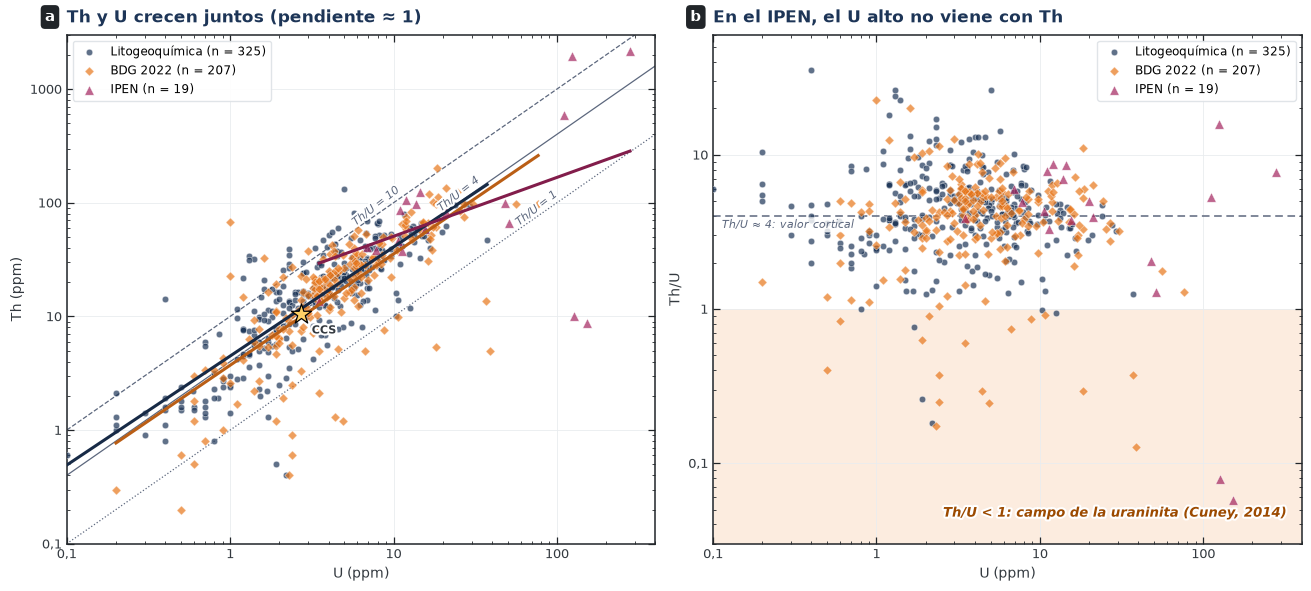

In [5]:
'''Figura 1: (a) Th frente a U y (b) Th/U frente a U, por fuente'''

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.8), layout='constrained')
RANGO_U = (0.1, 400)

for fuente in FUENTES_TH:
    t = con_th[con_th.fuente == fuente]
    color, marcador = graf.COLORES_FUENTE[fuente], graf.MARCADOR_FUENTE[fuente]
    tamano = 22 if len(t) > 50 else 46
    for ax, y in ((ax1, t.Th_ppm), (ax2, t.Th_U)):
        ax.scatter(t.U_ppm, y, s=tamano, color=color, marker=marcador, alpha=0.7, edgecolor='white', lw=0.4,
                   label=f'{fuente} (n = {len(t)})', zorder=3)
    '''Recta ajustada en log-log, solo donde hay datos'''
    f = relacion_th.loc[fuente]
    x = np.logspace(np.log10(t.U_ppm.min()), np.log10(t.U_ppm.max()), 50)
    ajuste = estadistica.regresion_log(t.U_ppm, t.Th_ppm, log_x=True)
    ax1.plot(x, 10 ** (ajuste['intercepto'] + ajuste['pendiente'] * np.log10(x)), color=graf.oscurecer(color, 0.2),
             lw=2.2, zorder=4)

'''(a) Th frente a U con rectas de Th/U constante'''
ax1.set(xscale='log', yscale='log', xlim=RANGO_U, ylim=(0.1, 3000), xlabel='U (ppm)', ylabel='Th (ppm)')
for r, estilo, x_texto in [(1, ':', 60), (4, '-', 20), (10, '--', 6)]:
    graf.razon_constante(ax1, r, f'Th/U = {r}', x_texto, ls=estilo)
graf.punto_ref(ax1, graf.CCS['U'], graf.CCS['Th'], 'CCS', dx=8, dy=-14)
ax1.legend(loc='upper left', fontsize=8.5)
ax1.set_title('Th y U crecen juntos (pendiente ≈ 1)', loc='left')
graf.letra(ax1, 'a')

'''(b) Th/U frente a U: si el U se enriquece sin Th, la razón cae'''
ax2.set(xscale='log', yscale='log', xlim=RANGO_U, ylim=(0.03, 60), xlabel='U (ppm)', ylabel='Th/U')
ax2.axhspan(0.03, 1, color=graf.COLOR_BANDA, alpha=0.2, lw=0, zorder=0.5)
graf.campo(ax2, 0.97, 0.06, 'Th/U < 1: campo de la uraninita (Cuney, 2014)', ha='right', color='#9c4a00')
graf.linea_ref(ax2, 4, 'Th/U ≈ 4: valor cortical', pos=0.015, lado='abajo')
ax2.legend(loc='upper right', fontsize=8.5)
ax2.set_title('En el IPEN, el U alto no viene con Th', loc='left')
graf.letra(ax2, 'b')

for ax in (ax1, ax2):
    graf.marco(ax)
    graf.ejes_log_planos(ax)

graf.guardar(fig, 'GC03_01_uranio_torio.png', svg=True)

Las rocas con Th/U < 1 son las candidatas a contener U en forma lixiviable (campo de la uraninita de Cuney, 2014):

In [6]:
'''Rocas de caja en el campo de la uraninita (Th/U < 1) y con U enriquecido (≥ 5 ppm, el doble de la corteza)'''
en_campo = con_th[con_th.Th_U < 1]
uraninita = en_campo[en_campo.U_ppm >= 5].sort_values('U_ppm', ascending=False)
print(f'Rocas con Th/U < 1: {len(en_campo)}; con U ≥ 5 ppm: {len(uraninita)}')
uraninita[['fuente', 'codigo', 'U_ppm', 'Th_ppm', 'Th_U', 'SiO2_pct', 'en_labor_minera']]

Rocas con Th/U < 1: 23; con U ≥ 5 ppm: 10


,fuente,codigo,U_ppm,Th_ppm,Th_U,SiO2_pct,en_labor_minera
572,IPEN,SR-8,152.0,8.8,0.06,NaN,False
578,IPEN,SR-1.5,127.0,10.0,0.08,NaN,False
337,BDG 2022,24n-RGQ24-019,39.0,5.0,0.13,NaN,True
341,BDG 2022,24n-RGQ23-024,36.9,13.8,0.37,72.27,True
421,BDG 2022,23m-RMT-071,18.3,5.4,0.30,NaN,True
96,Litogeoquímica,GR64A-19-101,12.6,11.9,0.94,74.18,False
376,BDG 2022,23m-RGQ23-036,10.7,9.8,0.92,NaN,True
97,Litogeoquímica,GR64A-19-051,10.3,10.1,0.98,72.34,False
463,BDG 2022,23m-RMT-045,8.8,7.6,0.86,NaN,True
468,BDG 2022,23m-RMT-018,6.7,5.0,0.75,NaN,True


**Lectura:** el U y el Th están fuertemente correlacionados en las dos fuentes regionales (ρ = 0,81 en la
litogeoquímica y 0,76 en BDG 2022), y la pendiente log-log es prácticamente 1 (0,96 y 0,98, con intervalos que
incluyen el 1): el Th crece en la misma proporción que el U y la razón se mantiene cerca de 4,3. Es la firma de un U
alojado con el Th en minerales accesorios del magma, como se interpretó en GC01.

El IPEN es la excepción: la correlación es débil y no significativa (ρ = 0,33; p = 0,17) y la pendiente es de 0,52.
Las rocas del IPEN con más U no tienen más Th, y su Th/U cae hacia el campo de la uraninita (figura 1b). De las 23
rocas con Th/U < 1, solo 10 tienen U ≥ 5 ppm; las demás son rocas pobres en ambos elementos, incluidas calizas, en las
que un Th/U bajo es normal y no indica U lixiviable. Entre las 10 destacan las dos muestras del IPEN (152 y 127 ppm;
Th/U de 0,06 a 0,08), seis muestras de BDG tomadas en labores mineras y dos granitos de la litogeoquímica con 72 a 74 %
de SiO₂ y Th/U apenas inferior a 1. Ese conjunto señala dónde el U fue añadido o redistribuido después de la
cristalización, que es el proceso que forma los depósitos (Cuney, 2014).

***

<a id="parte-3"></a>

## <span style="color:#e8761a">**3. URANIO Y SIO₂**</span>
***

En GC01 se observó que el U aumenta con el SiO₂ en la litogeoquímica y casi no lo hace en BDG 2022. Aquí se cuantifica
con una recta en escala logarítmica, cuya pendiente se expresa como el factor por el que se multiplica el U cada
10 % de SiO₂, con su intervalo de confianza. Se repite el ajuste solo en las rocas graníticas (SiO₂ ≥ 65 %) para
saber si la relación continúa dentro de los granitos, que son el blanco de la prospección.

In [7]:
'''Rocas con SiO2 entre 40 y 80 % (fuera de ese rango son carbonatos, sal o yeso, no rocas ígneas)'''
FUENTES_SI = ['Litogeoquímica', 'BDG 2022']
con_si = rocas[rocas.SiO2_pct.between(40, 80) & rocas.fuente.isin(FUENTES_SI)]

'''Recta log10(U) = a + b·SiO2: 10^(10·b) es el factor por el que se multiplica el U por cada 10 % de SiO2'''
filas = []
for fuente in FUENTES_SI:
    for nombre, t in [('todas', con_si[con_si.fuente == fuente]),
                      ('SiO2 ≥ 65 %', con_si[(con_si.fuente == fuente) & (con_si.SiO2_pct >= 65)])]:
        rho, p = stats.spearmanr(t.SiO2_pct, t.U_ppm)
        ajuste = estadistica.regresion_log(t.SiO2_pct, t.U_ppm)
        filas.append({'fuente': fuente, 'rocas': nombre, 'n': len(t), 'ρ de Spearman': rho, 'p': p,
                      'factor cada 10 % SiO2': 10 ** (10 * ajuste['pendiente']),
                      'IC 95 %': f'{10 ** (10 * ajuste["pend_inf"]):.2f} a {10 ** (10 * ajuste["pend_sup"]):.2f}',
                      'r²': ajuste['r2']})
relacion_si = pd.DataFrame(filas).set_index(['fuente', 'rocas'])
relacion_si

n  ρ de Spearman         p  \
fuente         rocas                                       
Litogeoquímica todas        312       5.14e-01  1.78e-22   
               SiO2 ≥ 65 %  192       2.88e-01  5.16e-05   
BDG 2022       todas        122       1.59e-01  8.07e-02   
               SiO2 ≥ 65 %   78      -6.68e-03  9.54e-01   

                            factor cada 10 % SiO2      IC 95 %        r²  
fuente         rocas                                                      
Litogeoquímica todas                         1.87  1.70 a 2.07  3.37e-01  
               SiO2 ≥ 65 %                   1.97  1.38 a 2.82  6.93e-02  
BDG 2022       todas                         1.21  1.01 a 1.44  3.69e-02  
               SiO2 ≥ 65 %                   1.00  0.55 a 1.84  8.08e-07

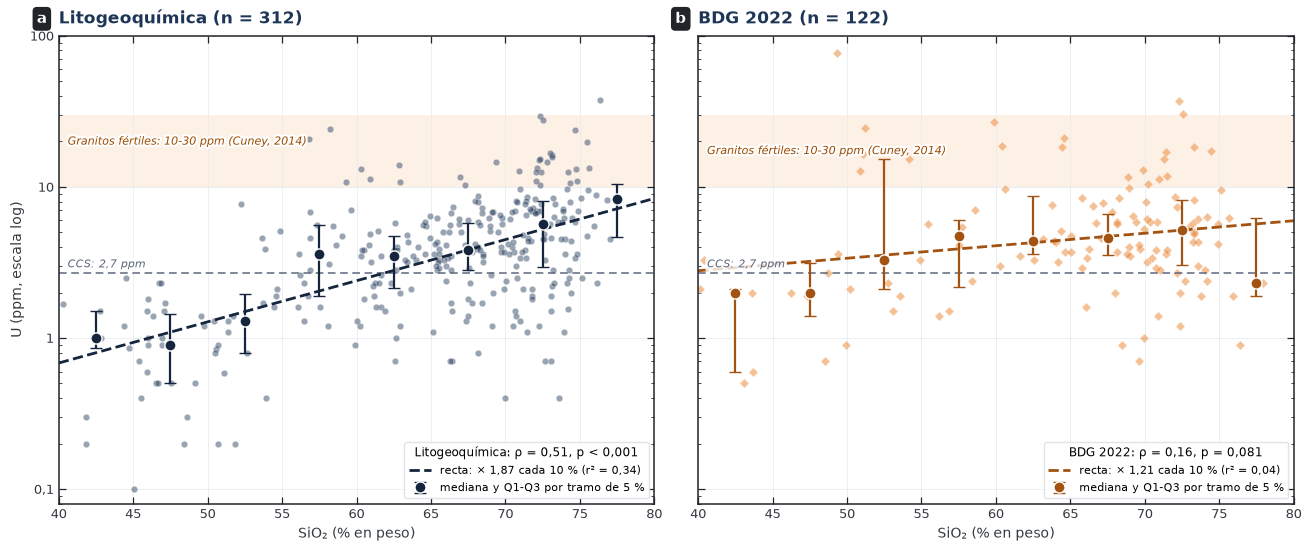

In [8]:
'''Figura 2: U frente a SiO2 en las dos fuentes regionales, con la recta log-lineal y la mediana por tramos'''

fig, ejes = plt.subplots(1, 2, figsize=(13, 5.4), sharey=True, layout='constrained')
TRAMOS = np.arange(40, 81, 5)
x = np.linspace(40, 80, 50)

for ax, fuente, letra in zip(ejes, FUENTES_SI, 'ab'):
    t = con_si[con_si.fuente == fuente]
    color, marcador = graf.COLORES_FUENTE[fuente], graf.MARCADOR_FUENTE[fuente]
    ax.scatter(t.SiO2_pct, t.U_ppm, s=22, color=color, marker=marcador, alpha=0.45, edgecolor='white', lw=0.4)
    '''Mediana y rango intercuartil por tramo de 5 % (tramos con 3 rocas o más)'''
    tramo = estadistica.mediana_por_tramo(t, 'SiO2_pct', 'U_ppm', TRAMOS)
    ax.errorbar(tramo.x, tramo['med'], yerr=[tramo['med'] - tramo.q1, tramo.q3 - tramo['med']], fmt='o', ms=8,
                color=graf.oscurecer(color, 0.3), mec='white', capsize=4, lw=1.6, label='mediana y Q1-Q3 por tramo de 5 %',
                zorder=5)
    '''Recta ajustada'''
    ajuste = estadistica.regresion_log(t.SiO2_pct, t.U_ppm)
    f = relacion_si.loc[(fuente, 'todas')]
    ax.plot(x, 10 ** (ajuste['intercepto'] + ajuste['pendiente'] * x), color=graf.oscurecer(color, 0.3), lw=2, ls='--',
            label=f'recta: × {graf.numero_es(f["factor cada 10 % SiO2"], 2)} cada 10 % (r² = {graf.numero_es(f["r²"], 2)})')
    graf.linea_ref(ax, graf.CCS['U'], 'CCS: 2,7 ppm', pos=0.015)
    graf.banda_ref(ax, 10, 30, 'Granitos fértiles: 10-30 ppm (Cuney, 2014)')
    ax.set(yscale='log', xlim=(40, 80), ylim=(0.08, 100), xlabel='SiO₂ (% en peso)')
    ax.legend(loc='lower right', fontsize=8, title=f'{fuente}: ρ = {graf.numero_es(f["ρ de Spearman"], 2)}, '
              f'{graf.texto_p(f["p"])}', title_fontsize=8.5)
    ax.set_title(f'{fuente} (n = {len(t)})', loc='left')
    graf.letra(ax, letra)
    graf.marco(ax)
    graf.ejes_log_planos(ax, 'y')
ejes[0].set_ylabel('U (ppm, escala log)')

graf.guardar(fig, 'GC03_02_uranio_silice.png', svg=True)

**Lectura:** en la litogeoquímica, el U se multiplica por 1,87 cada 10 % de SiO₂ (IC 95 %: 1,70 a 2,07; ρ = 0,51), y la
relación continúa dentro de los granitos (× 1,97 por encima de 65 % de SiO₂; ρ = 0,29; p < 0,001), aunque allí explica
muy poco de la variación (r² = 0,07). En BDG 2022, el factor es de solo 1,21 (1,01 a 1,44) y desaparece dentro de los
granitos (× 1,00). Los intervalos de las dos fuentes no se superponen, de modo que la diferencia es real.

Esta diferencia es coherente con GC02: BDG muestreó sobre todo labores mineras, donde la alteración hidrotermal
redistribuye el U y desacopla su contenido del grado de diferenciación de la roca. Incluso en la litogeoquímica, el
SiO₂ explica solo un tercio de la variación del U (r² = 0,34): la diferenciación magmática es condición necesaria,
pero no suficiente, para un granito enriquecido en U.

***

<a id="parte-4"></a>

## <span style="color:#e8761a">**4. URANIO EN ROCA Y BERILIO EN SEDIMENTOS**</span>
***

En el área no hay U en los sedimentos de quebrada, pero sí Be, La e Y. La comparación entre una roca y un sedimento
plantea un problema de soporte: la roca es un punto y el sedimento integra la cuenca aguas arriba. Se aplican dos
aproximaciones complementarias: el **sedimento más cercano** a cada roca, con varias distancias máximas, y la
**agregación en celdas**, que compara las medianas de ambos medios en la misma superficie.

In [9]:
'''Sedimento con Be más cercano a cada roca y su distancia'''
vecino = espacial.vecino_mas_cercano(rocas, sed_be, ['Be_ppm', 'La_ppm', 'Y_ppm'])
rocas = rocas.join(vecino.add_suffix('_sed').rename(columns={'dist_vecino_m_sed': 'dist_sed_m'}))

'''Sensibilidad a la distancia máxima entre la roca y el sedimento'''
filas = []
for distancia in [1000, 2000, 3000, 5000]:
    cerca = rocas[rocas.dist_sed_m <= distancia]
    fila = {'distancia máx. (km)': distancia / 1000, 'rocas': len(cerca)}
    for elemento in ['Be', 'La', 'Y']:
        fila[f'ρ U - {elemento}'], fila[f'p {elemento}'] = stats.spearmanr(cerca.U_ppm, cerca[f'{elemento}_ppm_sed'])
    filas.append(fila)
sensibilidad_sed = pd.DataFrame(filas).set_index('distancia máx. (km)')
sensibilidad_sed

,rocas,ρ U - Be,p Be,ρ U - La,p La,ρ U - Y,p Y
distancia máx. (km),,,,,,,
1.0,184,0.45,1.15e-10,0.21,4.90e-03,0.33,3.61e-06
2.0,385,0.41,7.77e-17,0.19,2.02e-04,0.29,8.06e-09
3.0,487,0.38,3.97e-18,0.22,6.27e-07,0.31,3.74e-12
5.0,561,0.38,5.10e-21,0.23,4.44e-08,0.30,5.91e-13


Las rocas con más U y los sedimentos con más Be podrían coincidir solo porque ambos son más frecuentes a menor
elevación, en los valles donde afloran los granitos. Se comprueba con la correlación parcial y por fuente:

In [10]:
'''Rocas con un sedimento a menos de 2 km: correlación simple, parcial y por fuente'''
cerca = rocas[rocas.dist_sed_m <= 2000]
elevacion_cerca = espacial.muestrear_raster(ARCHIVOS['dem_90m'], cerca)
lito_cerca = cerca[cerca.fuente == 'Litogeoquímica']
bdg_cerca = cerca[cerca.fuente == 'BDG 2022']
pruebas = {
    'simple (todas las fuentes)': stats.spearmanr(cerca.U_ppm, cerca.Be_ppm_sed),
    'descontando la elevación': estadistica.correlacion_parcial(cerca.U_ppm, cerca.Be_ppm_sed, elevacion_cerca),
    'descontando la posición este': estadistica.correlacion_parcial(cerca.U_ppm, cerca.Be_ppm_sed, cerca.geometry.x),
    'solo litogeoquímica': stats.spearmanr(lito_cerca.U_ppm, lito_cerca.Be_ppm_sed),
    'solo BDG 2022': stats.spearmanr(bdg_cerca.U_ppm, bdg_cerca.Be_ppm_sed),
}
pd.DataFrame({nombre: {'ρ': r[0], 'p': r[1]} for nombre, r in pruebas.items()}).T

,ρ,p
simple (todas las fuentes),0.41,7.77e-17
descontando la elevación,0.37,1.19e-13
descontando la posición este,0.46,1.24e-21
solo litogeoquímica,0.30,8.64e-06
solo BDG 2022,0.47,2.73e-08


En celdas de 5 y 10 km se compara la mediana del U de las rocas con la mediana del Be de los sedimentos de la misma
celda:

In [11]:
'''Mediana del U de las rocas y del Be de los sedimentos en cada celda (solo celdas con ambos datos)'''
def medianas_por_celda(celda):
    u = pd.Series(rocas.U_ppm.values, index=espacial.celda_de(rocas, aoi, celda)).groupby(level=0).median()
    be = pd.Series(sed_be.Be_ppm.values, index=espacial.celda_de(sed_be, aoi, celda)).groupby(level=0).median()
    return pd.concat({'U_roca': u, 'Be_sedimento': be}, axis=1, join='inner')

celdas = {celda: medianas_por_celda(celda) for celda in (5000, 10000)}
pd.DataFrame({
    f'{celda // 1000} km': {'celdas con ambos': len(t), 'ρ de Spearman': stats.spearmanr(t.U_roca, t.Be_sedimento)[0],
                           'p': stats.spearmanr(t.U_roca, t.Be_sedimento)[1]}
    for celda, t in celdas.items()
}).T

,celdas con ambos,ρ de Spearman,p
5 km,115.0,0.38,2.21e-05
10 km,71.0,0.35,2.58e-03


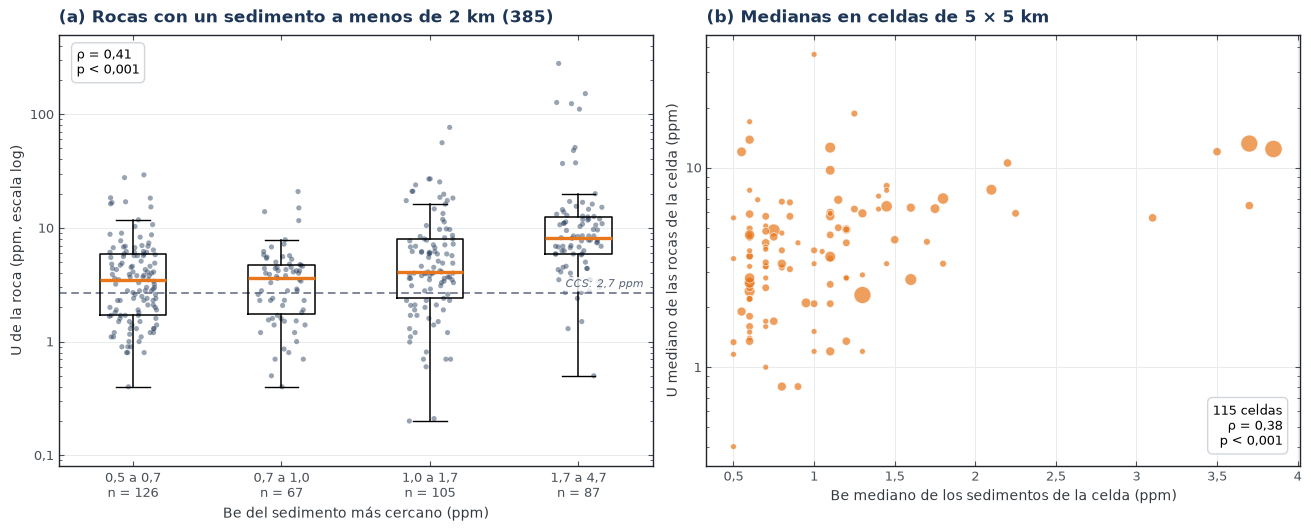

In [12]:
'''Figura 3: (a) U de la roca según el Be del sedimento más cercano (< 2 km) y (b) medianas en celdas de 5 km'''

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), layout='constrained')
rng = np.random.default_rng(0)

'''(a) Cuatro clases de Be (cuartiles del Be de los sedimentos cercanos)'''
cerca = rocas[rocas.dist_sed_m <= 2000].copy()
cerca['clase_Be'] = pd.qcut(cerca.Be_ppm_sed, 4, duplicates='drop')
clases = cerca.clase_Be.cat.categories
valores = [cerca.loc[cerca.clase_Be == c, 'U_ppm'] for c in clases]
for i, v in enumerate(valores):
    ax1.scatter(i + rng.uniform(-0.16, 0.16, len(v)), v, s=14, color=graf.AZUL, alpha=0.45, edgecolor='none')
ax1.boxplot(valores, positions=range(len(clases)), widths=0.45, showfliers=False,
            medianprops=dict(color=graf.NARANJA, lw=2.4), boxprops=dict(lw=1.1), whiskerprops=dict(lw=1.1))
ax1.set_xticks(range(len(clases)), [f'{graf.numero_es(c.left, 1)} a {graf.numero_es(c.right, 1)}\nn = {len(v)}'
                                     for c, v in zip(clases, valores)])
rho_be, p_be = stats.spearmanr(cerca.U_ppm, cerca.Be_ppm_sed)
graf.linea_ref(ax1, graf.CCS['U'], 'CCS: 2,7 ppm', pos=0.985)
ax1.set(yscale='log', ylim=(0.08, 500), xlabel='Be del sedimento más cercano (ppm)', ylabel='U de la roca (ppm, escala log)')
graf.cuadro_texto(ax1, f'ρ = {graf.numero_es(rho_be, 2)}\n{graf.texto_p(p_be)}', x=0.03, y=0.97, ha='left', va='top')
ax1.grid(axis='x', visible=False)
ax1.set_title(f'(a) Rocas con un sedimento a menos de 2 km ({len(cerca)})')
graf.ejes_log_planos(ax1, 'y')

'''(b) Celdas de 5 km: el tamaño del punto indica cuántas rocas hay en la celda'''
t = celdas[5000]
n_rocas = pd.Series(espacial.celda_de(rocas, aoi, 5000)).value_counts().reindex(t.index)
rho_c, p_c = stats.spearmanr(t.U_roca, t.Be_sedimento)
ax2.scatter(t.Be_sedimento, t.U_roca, s=12 + 6 * n_rocas, color=graf.NARANJA, alpha=0.7, edgecolor='white', lw=0.6)
ax2.set(yscale='log', xlabel='Be mediano de los sedimentos de la celda (ppm)', ylabel='U mediano de las rocas de la celda (ppm)')
graf.cuadro_texto(ax2, f'{len(t)} celdas\nρ = {graf.numero_es(rho_c, 2)}\n{graf.texto_p(p_c)}', x=0.97, y=0.04)
ax2.set_title('(b) Medianas en celdas de 5 × 5 km')
graf.ejes_log_planos(ax2, 'y')
graf.ejes_coma_decimal(ax2, y=False)

graf.guardar(fig, 'GC03_03_uranio_berilio.png', svg=True)

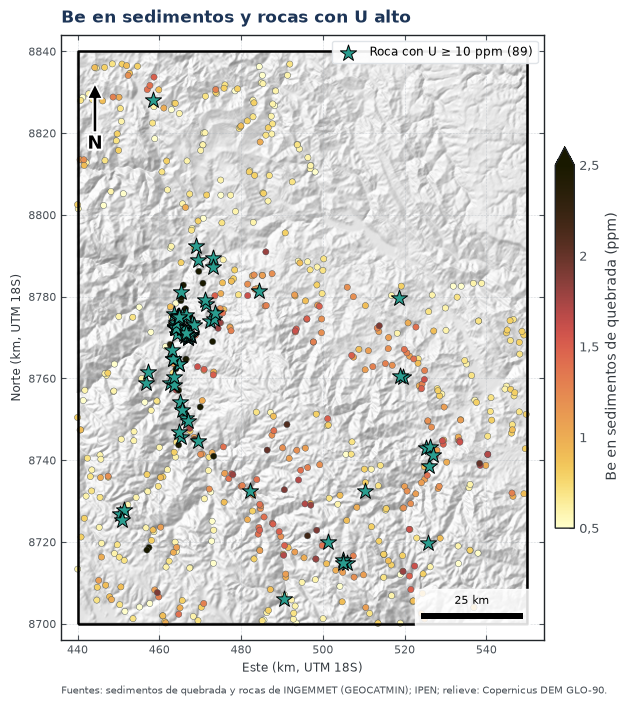

In [13]:
'''Figura 4: Be en los sedimentos y rocas con U ≥ 10 ppm (umbral inferior de los granitos fértiles)'''

fig, ax = plt.subplots(figsize=(7.5, 9))
graf.relieve(ax, elevacion, extension, opacidad=0.6)

'''Sedimentos coloreados por Be (los valores altos se dibujan encima)'''
orden = sed_be.sort_values('Be_ppm')
puntos = ax.scatter(orden.geometry.x, orden.geometry.y, c=orden.Be_ppm, cmap='cmc.lajolla_r', vmin=0.5, vmax=2.5,
                    s=20, edgecolor='#495057', lw=0.3, zorder=10)
barra = fig.colorbar(puntos, ax=ax, shrink=0.55, pad=0.02, extend='max', label='Be en sedimentos de quebrada (ppm)')
barra.set_ticks([0.5, 1, 1.5, 2, 2.5], labels=['0,5', '1', '1,5', '2', '2,5'])

'''Rocas con U ≥ 10 ppm'''
fertiles = rocas[rocas.U_ppm >= 10]
ax.scatter(fertiles.geometry.x, fertiles.geometry.y, marker='*', s=150, color='#2a9d8f', edgecolor='black', lw=0.7,
           zorder=12, label=f'Roca con U ≥ 10 ppm ({len(fertiles)})')
ax.legend(loc='upper right', fontsize=8.5).set_zorder(50)
graf.marco_mapa(ax, aoi, 'Be en sedimentos y rocas con U alto')
graf.fuente_al_pie(ax, 'Fuentes: sedimentos de quebrada y rocas de INGEMMET (GEOCATMIN); IPEN; relieve: Copernicus DEM GLO-90.')

graf.guardar(fig, 'GC03_04_mapa_berilio.png')

**Lectura:** el U de la roca se relaciona con el Be del sedimento más cercano con una correlación moderada (ρ = 0,45 a
menos de 1 km y 0,38 a menos de 5 km), que se mantiene al descontar la elevación (0,37) y la posición este (0,46) y
aparece en cada fuente por separado (0,30 en la litogeoquímica y 0,47 en BDG 2022). Agregada en celdas, la relación
persiste (ρ = 0,38 en 115 celdas de 5 km y 0,35 en 71 celdas de 10 km), lo que indica que no depende de cómo se
empareje cada roca con un sedimento. Las rocas cercanas a sedimentos con más de 1,7 ppm de Be tienen una mediana de U
de unos 8 ppm, frente a unos 3,5 ppm cuando el Be es menor que 1 ppm (figura 3a).

El Be se relaciona con el U más que el La (ρ ≈ 0,2) y el Y (ρ ≈ 0,3). Es coherente con que el Be, como el U, se
concentre en los granitos más evolucionados y en sus pegmatitas, mientras que el La también abunda en rocas menos
diferenciadas. En el mapa (figura 4), los sedimentos con más Be se agrupan alrededor del granito de San Ramón, donde se
concentran las rocas con U ≥ 10 ppm.

> Limitación: el 18 % de los sedimentos tiene Be por debajo del límite de detección y los valores medidos tienen poca
> resolución (0,5 a 0,8 ppm en la mitad de las muestras), lo que reduce la correlación observable.

***

<a id="parte-5"></a>

## <span style="color:#e8761a">**5. URANIO Y GRAVEDAD**</span>
***

La anomalía de Bouguer del área disminuye de este a oeste, unos 150 mGal en 110 km, porque la corteza se engrosa bajo
la cordillera. Si el U también cambia de este a oeste, ambas variables aparecerán correlacionadas aunque no tengan
relación física. Por ello se calcula, además de la correlación simple, la **correlación parcial** que descuenta la
posición este-oeste (`estadistica.correlacion_parcial`).

In [14]:
'''Anomalía de Bouguer del modelo en la superficie (GC02), en UTM con celdas de 1 km'''
bouguer, ext_g = espacial.raster_a_utm(ARCHIVOS['gravedad_xgm2019e_superficie'], aoi, celda=1000, margen=0)
rocas['bouguer_mgal'] = espacial.muestrear_raster(ARCHIVOS['gravedad_xgm2019e_superficie'], rocas)
rocas['este_km'] = rocas.geometry.x / 1000

'''Correlación simple y correlación parcial descontando la posición este-oeste'''
rho_g, p_g = stats.spearmanr(rocas.U_ppm, rocas.bouguer_mgal)
rho_ge, _ = stats.spearmanr(rocas.bouguer_mgal, rocas.este_km)
rho_ue, p_ue = stats.spearmanr(rocas.U_ppm, rocas.este_km)
rho_parcial, p_parcial = estadistica.correlacion_parcial(rocas.U_ppm, rocas.bouguer_mgal, rocas.este_km)
print(f'ρ (U, Bouguer) = {graf.numero_es(rho_g, 2)} ({graf.texto_p(p_g)})')
print(f'ρ (Bouguer, este) = {graf.numero_es(rho_ge, 2)} | ρ (U, este) = {graf.numero_es(rho_ue, 2)} ({graf.texto_p(p_ue)})')
print(f'ρ parcial (U, Bouguer | este) = {graf.numero_es(rho_parcial, 2)} ({graf.texto_p(p_parcial)})')

'''Medianas por franjas de 30 km de oeste a este'''
franja = pd.cut(rocas.este_km, [440, 470, 500, 530, 550])
rocas.groupby(franja, observed=True).agg(rocas=('U_ppm', 'size'), U_mediana=('U_ppm', 'median'),
                                          Bouguer_mediana=('bouguer_mgal', 'median'))

ρ (U, Bouguer) = -0,12 (p = 0,004)
ρ (Bouguer, este) = 0,72 | ρ (U, este) = -0,14 (p < 0,001)
ρ parcial (U, Bouguer | este) = -0,03 (p = 0,501)


,rocas,U_mediana,Bouguer_mediana
este_km,,,
"(440, 470]",298,4.55,-291.20
"(470, 500]",96,4.55,-244.41
"(500, 530]",157,3.20,-219.88
"(530, 550]",36,1.75,-190.47


La señal de un plutón se busca en la **anomalía residual**: la anomalía menos su parte regional, estimada con un
filtro gaussiano (`gravedad.separar_regional`). El ancho del filtro es una decisión del analista, por lo que se
prueban tres valores y se considera robusto solo lo que se repite en los tres. Se comparan las rocas con U ≥ 10 ppm,
umbral inferior de los granitos fértiles de Cuney (2014), con el resto.

In [15]:
'''Anomalía residual para tres anchos del filtro regional y U alto (≥ 10 ppm) frente a U bajo'''
alto = rocas.U_ppm >= 10
residuales, filas = {}, []
for sigma_km in (15, 25, 40):
    regional, residual = gravedad.separar_regional(bouguer, celda=1000, sigma_m=sigma_km * 1000)
    residuales[sigma_km] = residual
    valor = pd.Series(espacial.muestrear_matriz(residual, ext_g, rocas), index=rocas.index)
    filas.append({
        'σ del filtro (km)': sigma_km, 'desv. del residual (mGal)': np.nanstd(residual),
        'mediana U ≥ 10 ppm': valor[alto].median(), 'mediana U < 10 ppm': valor[~alto].median(),
        'p de Mann-Whitney': stats.mannwhitneyu(valor[alto], valor[~alto]).pvalue,
        'ρ (U, residual)': stats.spearmanr(rocas.U_ppm, valor)[0],
    })
    if sigma_km == 25:
        rocas['residual_25km'] = valor
residual_u = pd.DataFrame(filas).set_index('σ del filtro (km)')
print(f'Rocas con U ≥ 10 ppm: {alto.sum()} de {len(rocas)}')
residual_u

Rocas con U ≥ 10 ppm: 89 de 587


,desv. del residual (mGal),mediana U ≥ 10 ppm,mediana U < 10 ppm,p de Mann-Whitney,"ρ (U, residual)"
σ del filtro (km),,,,,
15,6.66,4.26,-0.41,4.59e-04,0.09
25,10.95,2.55,-2.11,1.97e-02,0.02
40,18.20,-2.57,-5.30,5.50e-01,-0.05


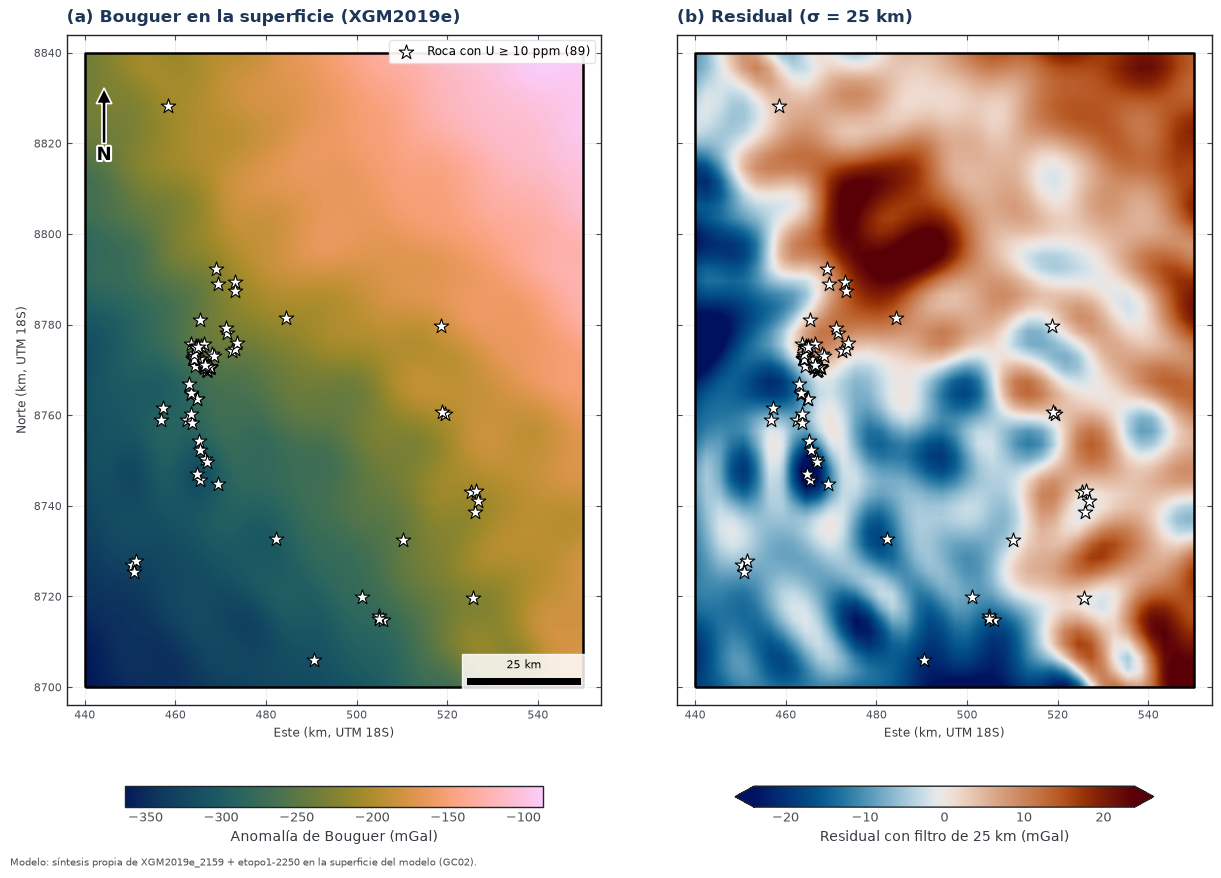

In [16]:
'''Figura 5: (a) anomalía de Bouguer en la superficie y (b) residual con un filtro de 25 km, con las rocas de U alto'''

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 8.4), sharey=True, layout='constrained')

'''(a) Anomalía total: domina el gradiente oeste-este'''
im1 = ax1.imshow(bouguer, extent=ext_g, cmap=graf.CMAP_CONTINUO, interpolation='bilinear', zorder=1)
graf.relieve(ax1, elevacion, extension, opacidad=0.18)
fig.colorbar(im1, ax=ax1, orientation='horizontal', shrink=0.7, pad=0.06, label='Anomalía de Bouguer (mGal)')

'''(b) Residual: lo que queda al quitar la regional'''
limite = np.nanpercentile(np.abs(residuales[25]), 98)
im2 = ax2.imshow(residuales[25], extent=ext_g, cmap=graf.CMAP_DIVERGENTE, norm=TwoSlopeNorm(0, -limite, limite),
                 interpolation='bilinear', zorder=1)
graf.relieve(ax2, elevacion, extension, opacidad=0.18)
fig.colorbar(im2, ax=ax2, orientation='horizontal', shrink=0.7, pad=0.06, extend='both',
             label='Residual con filtro de 25 km (mGal)')

for ax, titulo, letra in ((ax1, 'Bouguer en la superficie (XGM2019e)', 'a'), (ax2, 'Residual (σ = 25 km)', 'b')):
    ax.scatter(fertiles.geometry.x, fertiles.geometry.y, marker='*', s=120, color='white', edgecolor='black', lw=0.8,
               zorder=12, label=f'Roca con U ≥ 10 ppm ({len(fertiles)})')
    graf.marco_mapa(ax, aoi, f'({letra}) {titulo}', accesorios=letra == 'a')
ax1.legend(loc='upper right', fontsize=8.5).set_zorder(50)
ax2.set_ylabel('')
graf.fuente_figura(fig, 'Modelo: síntesis propia de XGM2019e_2159 + etopo1-2250 en la superficie del modelo (GC02).')

graf.guardar(fig, 'GC03_05_mapas_gravedad.png')

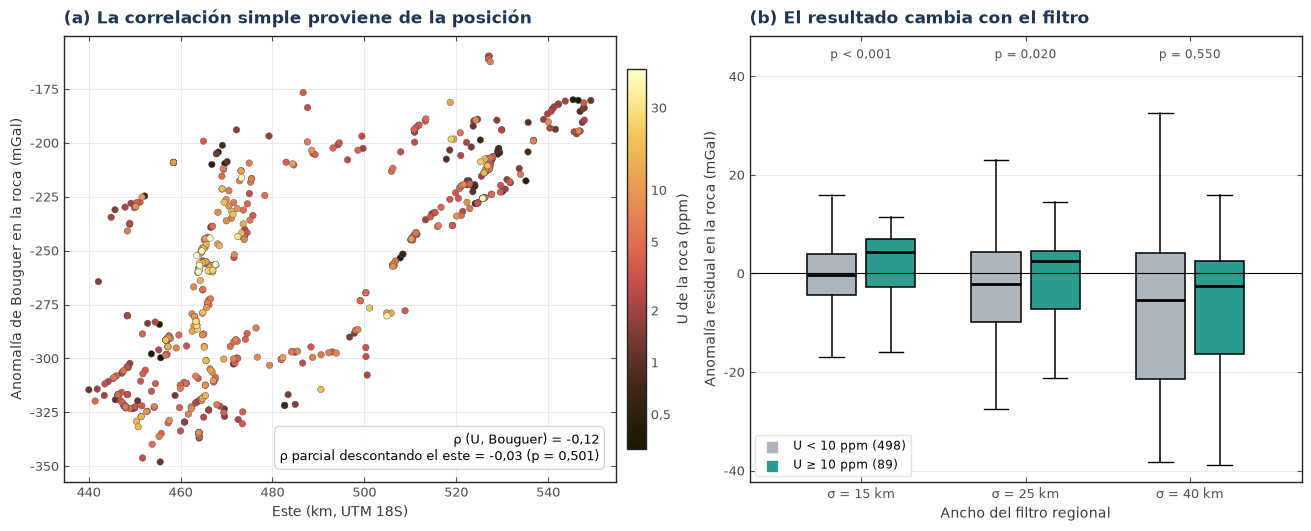

In [17]:
'''Figura 6: (a) U y Bouguer cambian los dos de oeste a este y (b) U alto frente a U bajo en el residual'''

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), layout='constrained')

'''(a) Bouguer frente a la posición este, coloreado por el U de la roca'''
orden = rocas.sort_values('U_ppm')
puntos = ax1.scatter(orden.este_km, orden.bouguer_mgal, c=np.log10(orden.U_ppm), cmap='cmc.lajolla', s=22,
                     edgecolor='#495057', lw=0.3, vmin=-0.5, vmax=1.7)
barra = fig.colorbar(puntos, ax=ax1, shrink=0.85, pad=0.02)
barra.set_ticks(np.log10([0.5, 1, 2, 5, 10, 30]), labels=['0,5', '1', '2', '5', '10', '30'])
barra.set_label('U de la roca (ppm)')
ax1.set(xlabel='Este (km, UTM 18S)', ylabel='Anomalía de Bouguer en la roca (mGal)')
graf.cuadro_texto(ax1, f'ρ (U, Bouguer) = {graf.numero_es(rho_g, 2)}\n'
                       f'ρ parcial descontando el este = {graf.numero_es(rho_parcial, 2)} ({graf.texto_p(p_parcial)})')
ax1.set_title('(a) La correlación simple proviene de la posición')

'''(b) Residual en las rocas de U alto y bajo para cada ancho del filtro'''
for k, (etiqueta, grupo, color) in enumerate([('U < 10 ppm', ~alto, '#adb5bd'), ('U ≥ 10 ppm', alto, '#2a9d8f')]):
    valores = []
    for sigma_km, residual in residuales.items():
        valores.append(espacial.muestrear_matriz(residual, ext_g, rocas[grupo]))
    posiciones = np.arange(3) + (k - 0.5) * 0.36
    caja = ax2.boxplot(valores, positions=posiciones, widths=0.3, showfliers=False, patch_artist=True,
                       medianprops=dict(color='black', lw=2), boxprops=dict(lw=1.1, facecolor=color),
                       whiskerprops=dict(lw=1.1))
    ax2.scatter([], [], marker='s', s=60, color=color, label=f'{etiqueta} ({grupo.sum()})')
for i, (sigma_km, f) in enumerate(residual_u.iterrows()):
    ax2.text(i, 0.97, graf.texto_p(f['p de Mann-Whitney']), transform=ax2.get_xaxis_transform(), ha='center',
             va='top', fontsize=8.5, color=graf.GRIS)
ax2.axhline(0, color='black', lw=0.8)
ax2.set_xticks(range(3), [f'σ = {s} km' for s in residuales])
ax2.set(xlabel='Ancho del filtro regional', ylabel='Anomalía residual en la roca (mGal)')
ax2.set_ylim(top=ax2.get_ylim()[1] + 12)
ax2.legend(loc='lower left', fontsize=8.5)
ax2.grid(axis='x', visible=False)
ax2.set_title('(b) El resultado cambia con el filtro')

for ax in (ax1, ax2):
    graf.ejes_coma_decimal(ax, x=ax is ax1)

graf.guardar(fig, 'GC03_06_uranio_gravedad.png', svg=True)

**Lectura:** la correlación simple entre el U y la anomalía de Bouguer es débil y significativa (ρ = −0,12;
p = 0,004), pero no indica una relación física: la anomalía depende fuertemente de la posición este-oeste (ρ = 0,72) y
el U también disminuye hacia el este (de 4,6 ppm de mediana en el oeste a 1,8 ppm en el extremo este). Al descontar
la posición, la correlación desaparece (ρ parcial = −0,03; p = 0,50). Por ello, la anomalía total no debe emplearse
como indicador de U: actúa como un sustituto de la posición geográfica.

La anomalía residual tampoco muestra una relación robusta. Con filtros de 15 y 25 km, las rocas con U ≥ 10 ppm se
ubican en residuales algo más positivos que el resto (+4,3 frente a −0,4 mGal y +2,6 frente a −2,1 mGal), lo contrario
de lo esperado para un granito menos denso que su encajante; con 40 km la diferencia desaparece (p = 0,55), y la
correlación con el U es nula con los tres filtros (|ρ| ≤ 0,09). Un resultado que cambia de signo y de significación con
una decisión del analista no es una relación geológica.

Dos razones lo explican: la resolución del modelo (~9 km) es comparable al tamaño de los plutones, y el granito de San
Ramón se ubica sobre el gradiente entre el mínimo de la cordillera y el máximo subandino (figura 5), donde la
separación regional-residual es más sensible al filtro. Para detectar la señal de un plutón harían falta estaciones
densas sobre él, no un modelo global.

***

<a id="parte-6"></a>

## <span style="color:#e8761a">**6. SÍNTESIS: MATRIZ DE CORRELACIONES**</span>
***

La matriz resume todas las relaciones con todas las rocas de caja. Cada par se calcula con las rocas que tienen ambos
datos, de modo que el número de rocas cambia de un par a otro.

In [18]:
'''Variables de cada roca (el Be solo si el sedimento está a menos de 2 km)'''
rocas['elevacion_m'] = espacial.muestrear_raster(ARCHIVOS['dem_90m'], rocas)
VARIABLES = {
    'U': rocas.U_ppm, 'Th': rocas.Th_ppm.where(rocas.Th_ppm > 0), 'SiO₂': rocas.SiO2_pct.where(rocas.SiO2_pct.between(40, 80)),
    'Be sedimento': rocas.Be_ppm_sed.where(rocas.dist_sed_m <= 2000), 'Bouguer': rocas.bouguer_mgal,
    'Residual 25 km': rocas.residual_25km, 'Este': rocas.este_km, 'Elevación': rocas.elevacion_m,
}
tabla_var = pd.DataFrame(VARIABLES)

'''ρ de Spearman y número de rocas de cada par (cada par usa las rocas que tienen ambos datos)'''
nombres = list(VARIABLES)
rho = pd.DataFrame(index=nombres, columns=nombres, dtype=float)
n_par = rho.copy()
for a in nombres:
    for b in nombres:
        par = tabla_var[[a, b]].dropna()
        rho.loc[a, b] = stats.spearmanr(par[a], par[b])[0] if a != b else 1.0
        n_par.loc[a, b] = len(par)
rho.round(2)

,U,Th,SiO₂,Be sedimento,Bouguer,Residual 25 km,Este,Elevación
U,1.00,0.80,0.42,0.41,-0.12,0.02,-0.14,-0.23
Th,0.80,1.00,0.47,0.43,-0.01,0.11,-0.04,-0.27
SiO₂,0.42,0.47,1.00,0.24,-0.07,-0.04,-0.05,-0.17
Be sedimento,0.41,0.43,0.24,1.00,0.14,0.19,0.18,-0.35
Bouguer,-0.12,-0.01,-0.07,0.14,1.00,0.79,0.72,-0.51
Residual 25 km,0.02,0.11,-0.04,0.19,0.79,1.00,0.51,-0.41
Este,-0.14,-0.04,-0.05,0.18,0.72,0.51,1.00,-0.17
Elevación,-0.23,-0.27,-0.17,-0.35,-0.51,-0.41,-0.17,1.00


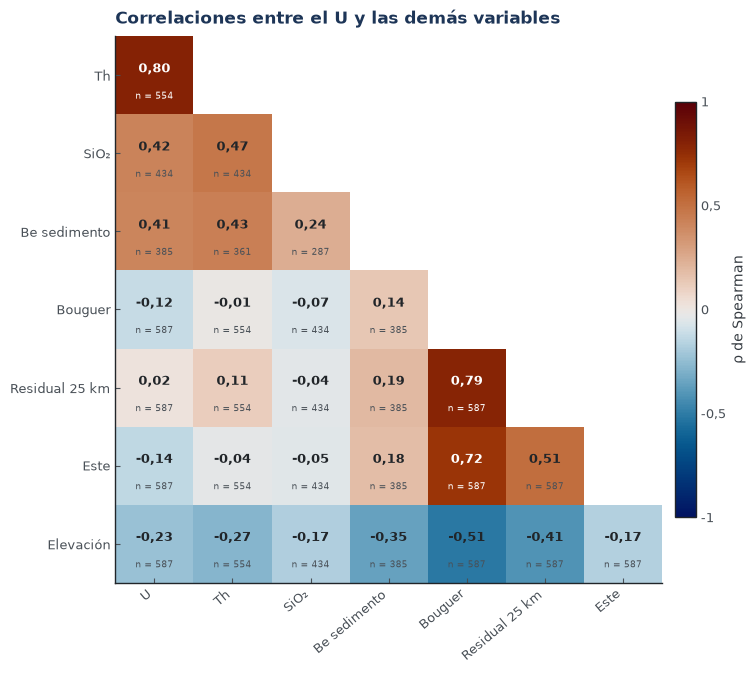

In [19]:
'''Figura 7: matriz de correlaciones de Spearman (triángulo inferior; el número pequeño es n)'''

fig, ax = plt.subplots(figsize=(8.5, 7.2))
filas_m, columnas_m = nombres[1:], nombres[:-1]          # sin la fila y la columna que quedarían vacías
sub = rho.loc[filas_m, columnas_m].values
mascara = np.triu(np.ones_like(sub, dtype=bool), k=1)
im = ax.imshow(np.where(mascara, np.nan, sub), cmap=graf.CMAP_DIVERGENTE, vmin=-1, vmax=1)
for i, a in enumerate(filas_m):
    for j, b in enumerate(columnas_m[:i + 1]):
        v = rho.loc[a, b]
        ax.text(j, i - 0.08, graf.numero_es(v, 2), ha='center', va='center', fontsize=9.5, fontweight='bold',
                color='white' if abs(v) > 0.55 else '#212529')
        ax.text(j, i + 0.27, f'n = {int(n_par.loc[a, b])}', ha='center', va='center', fontsize=6.5,
                color='white' if abs(v) > 0.55 else graf.GRIS)
ax.set_xticks(range(len(columnas_m)), columnas_m, rotation=40, ha='right')
ax.set_yticks(range(len(filas_m)), filas_m)
ax.tick_params(top=False, right=False)
ax.grid(False)
for lado in ('top', 'right'):
    ax.spines[lado].set_visible(False)
barra = fig.colorbar(im, ax=ax, shrink=0.75, pad=0.02, label='ρ de Spearman')
barra.set_ticks([-1, -0.5, 0, 0.5, 1], labels=['-1', '-0,5', '0', '0,5', '1'])
ax.set_title('Correlaciones entre el U y las demás variables')

graf.guardar(fig, 'GC03_07_matriz_correlaciones.png', svg=True)

**Lectura:** la matriz confirma el orden de las relaciones: el U se asocia con el Th de la misma roca (ρ = 0,80), con
el SiO₂ (0,42) y con el Be del sedimento cercano (0,41), y no con la gravedad (−0,12 la total y 0,02 la residual). El Be
del sedimento se relaciona con el Th casi tanto como con el U (0,43), lo que refuerza su lectura como indicador de
granitos evolucionados más que de U en particular.

La elevación se correlaciona negativamente con casi todo: con el U (−0,23), con el Be (−0,35) y con la anomalía de
Bouguer (−0,51, por la compensación isostática de la cordillera). Es un recordatorio de que en esta área la geografía
condiciona varias variables a la vez, y de que una correlación simple debe contrastarse con la parcial antes de
interpretarse.

***

<a id="parte-7"></a>

## <span style="color:#e8761a">**7. CONCLUSIONES**</span>
***

**Pregunta 3.** El uranio en roca se relaciona, en orden de fuerza, con:

| Variable | Relación con el U | ¿Robusta? | Interpretación |
|---|---|---|---|
| Th de la misma roca | ρ = 0,80; pendiente log-log ≈ 1 | Sí, en las dos fuentes regionales | U magmático alojado con el Th; las excepciones (Th/U < 1 con U alto, sobre todo en el IPEN) señalan U añadido o redistribuido |
| SiO₂ de la misma roca | × 1,87 cada 10 % en la litogeoquímica | Sí en la litogeoquímica; débil en BDG 2022 | La diferenciación concentra el U, pero explica solo un tercio de su variación |
| Be del sedimento cercano | ρ = 0,38 a 0,45 | Sí: con la distancia, en celdas, por fuente y descontando elevación y posición | Ambos marcan granitos evolucionados; el Be cubre áreas sin rocas analizadas |
| Anomalía de Bouguer total | ρ = −0,12 | No: desaparece al descontar la posición | Correlación espuria por el gradiente oeste-este |
| Anomalía residual | Depende del filtro | No | La resolución del modelo no alcanza la escala de un plutón |

**Implicaciones para la prospección:**
1. El Be de los sedimentos de quebrada, que cubre el área de forma mucho más amplia que las rocas (GC01, sección 9),
   es la variable más útil para extender la información del U a zonas sin muestreo de rocas.
2. El Th/U es más informativo que el U solo: las rocas con U alto y Th/U < 1 son las candidatas a U lixiviable.
3. La gravedad del modelo global no aporta información sobre el U a esta escala; su uso como variable de
   prospectividad requiere controlar la posición geográfica o disponer de estaciones densas.

**Limitaciones:**
- Las muestras no son aleatorias ni independientes: se agrupan en vías y en zonas de interés, y la autocorrelación
  espacial hace que los valores p sean optimistas. Por ello se han priorizado los resultados que se repiten con
  distintas distancias, celdas, fuentes y filtros, más que un valor p aislado.
- La roca y el sedimento tienen soportes distintos (un punto frente a una cuenca); el vecino más cercano y las celdas
  son aproximaciones, no una delimitación de cuencas.
- El Be tiene un 18 % de valores bajo el límite de detección y poca resolución analítica.
- La resolución del modelo de gravedad (~9 km) limita el análisis de cuerpos menores.

***

<a id="ia"></a>

## <span style="color:#e8761a">**DECLARACIÓN DE USO DE INTELIGENCIA ARTIFICIAL**</span>
***

Se utilizó una herramienta de inteligencia artificial generativa como apoyo en la edición estética de las gráficas:
formato, paleta de colores, tipografía y composición de las figuras.

***

<a id="referencias"></a>

## <span style="color:#e8761a">**REFERENCIAS**</span>
***

- Carpio et al. (2021). [*Prospección del litio en el norte y centro del Perú*](https://hdl.handle.net/20.500.12544/3542) (Boletín B-74). INGEMMET.
- Cuney, M. (2014). [Felsic magmatism and uranium deposits](https://doi.org/10.2113/gssgfbull.185.2.75). *Bulletin de la Société Géologique de France, 185*(2), 75-92.
- Mišković, A., Spikings, R. A., Chew, D. M., Košler, J., Ulianov, A., y Schaltegger, U. (2009). [Tectonomagmatic evolution of Western Amazonia: Geochemical characterization and zircon U-Pb geochronologic constraints from the Peruvian Eastern Cordilleran granitoids](https://doi.org/10.1130/B26488.1). *GSA Bulletin, 121*(9-10), 1298-1324.
- Rudnick, R. L., y Gao, S. (2003). [Composition of the continental crust](https://doi.org/10.1016/B0-08-043751-6/03016-4). En *Treatise on Geochemistry* (vol. 3, pp. 1-64). Elsevier.
- Valencia y Mamani (2013). En *Informe Científico Tecnológico 2011* (pp. 79-84). Instituto Peruano de Energía Nuclear.
- Valencia (2016). En *Informe Científico Tecnológico*, vol. 14 (p. 131). Instituto Peruano de Energía Nuclear.
- Zingerle, P., Pail, R., Gruber, T., y Oikonomidou, X. (2020). [The combined global gravity field model XGM2019e](https://doi.org/10.1007/s00190-020-01398-0). *Journal of Geodesy, 94*, 66.

***